# How much better is the best model?, per brain area → `figure_model_comparison_FEF.pdf`, `figure_model_comparison_DMFC.pdf`

[`../figure_4/figure_model_comparison.ipynb`](../figure_4/figure_model_comparison.ipynb)'s
panel, drawn once over FEF neurons and once over DMFC neurons, so a reader can see that neither
animal's result is carried by one recording site.

**What the point and its whisker are.** The point is the *population* estimate — the total
held-out log-likelihood difference over all neurons and trials, divided by the total trial
count — and the whisker is a **95% confidence interval of the mean across neurons**, with each
neuron treated as one independent observation regardless of session. What it does not cover is
session-to-session variation: simultaneously recorded neurons share trials, share a stimulus
sequence and have correlated receptive fields, so the session is the unit that is plausibly
independent, and the cluster-robust error across sessions is wider by `inflation`. Both are
computed here and printed beside each other, so the size of that gap is visible rather than
asserted. The axis is a likelihood rather than a log-likelihood: the reference sits at 1, and
0.91 means each held-out trial is 9% less likely under that model.

Nothing is refit: every number comes from the cached `dtest_ll_mean` (the paired per-split
held-out ΔLL against a constant fit to the same trials) times each neuron's trial count.
The area filter comes first, so the reference model and every difference are judged within
the population actually drawn.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import common
common.set_style()
import elpd_lib as el
import models_lib as ml

# ── These must match ../figure_4/figure_model_comparison.ipynb ────────────────
# The supplement is that panel over a conditioned population; if a knob here differs, the two
# are different analyses and the conditioning no longer shows what it claims to.
MODELS = (
    'weighted_average',
    'normalization',
    'inhibition',
    'basis_function',
    'future_field',
)
LABELS = ml.MODEL_LABELS_SHORT

N_BOOT = 2000          # session-level bootstrap draws

# ── Style, matched to ../figure_4/figure_model_comparison.ipynb ───────────────
# The accents of figure_ks_stats.ipynb, so the panels read together.
ACCENT, ACCENT_MODEL = '#c1272d', 'future_field'
SECOND_ACCENT, SECOND_ACCENT_MODEL = '#8e3b6b', 'basis_function'
GRAY_LIGHT, GRAY_DARK = 0.82, 0.2


def model_colors(models=MODELS):
    accents = {ACCENT_MODEL: ACCENT, SECOND_ACCENT_MODEL: SECOND_ACCENT}
    n_grey = sum(m not in accents for m in models)
    greys = iter(np.linspace(GRAY_LIGHT, GRAY_DARK, max(n_grey, 1)))
    return {m: (accents[m] if m in accents else str(next(greys))) for m in models}


COLORS = model_colors()
SUBJECTS = ('Perle', 'Elgar')
TITLES = {'Perle': 'Monkey P', 'Elgar': 'Monkey E'}

FIGSIZE = (5.5, 3.1)
OUTPUT = 'figure_model_comparison_{area}.pdf'
XTICK_ROTATION = -50   # degrees; 0 is horizontal
XTICK_HA = 'left'      # 'left' evenly spaces the labels' LEFT ends under their ticks ...
XTICK_SHIFT_IN = -0.2  # ... and puts the block right of them, which this shifts back

# WSPACE is constrained layout's MINIMUM gap and it bottoms out well short of zero — the right
# panel has its own y tick labels, since the animals do not share a scale. COLUMN_SHIFT_IN
# slides that panel left, in INCHES, after the layout has settled, which is the only way past
# the floor.
WSPACE = 0.08
COLUMN_SHIFT_IN = 0.35

POINT_SIZE = 10          # diameter of the summary marker, in points
ERR_LINEWIDTH = 1.2      # its error bar
ERR_CAPSIZE = 4

YLABEL = 'Relative likelihood'


## The comparison

One table per animal per area: the total held-out log-likelihood difference against the
reference, divided by the total trial count, with the 95% confidence interval across neurons
(what the figure draws) beside the cluster-robust standard error across sessions and the
session-level bootstrap. `inflation` is the ratio of the session-level and neuron-level standard
errors — how much a flat, neuron-level interval understates the session-to-session uncertainty.

In [2]:
fits = common.selected_fits_by_area(MODELS)

tables = {}
for area, summary in fits:
    print(f'══ {area} ' + '═' * 56)
    tables[area] = {}
    for s_ in SUBJECTS:
        t = el.elpd_table(summary, MODELS, subject=s_, n_boot=N_BOOT)
        tables[area][TITLES[s_]] = t
        print(f'── {TITLES[s_]} — reference: {t.attrs["reference"]} '
              f'({t["n_neurons"].iat[0]} neurons, {t["n_clusters"].iat[0]} sessions)')
        display(t[['model', 'delta_per_unit', 'neuron_ci_lo_per_unit',
                   'neuron_ci_hi_per_unit', 'se_cluster_per_unit', 'lo_per_unit',
                   'hi_per_unit', 'se_neuron_per_unit', 'inflation']].round(5))


2-object modulation (Benjamini-Hochberg FDR q = 0.05, deviance explained >= 0.02): 1339 of 3011 neurons (44.5%)
  significance alone would keep 1801; the deviance floor drops a further 462
  modulation criterion: 3186 -> 1339 neurons
FEF: 660 neurons enter the figure
DMFC: 679 neurons enter the figure
══ FEF ════════════════════════════════════════════════════════
── Monkey P — reference: future_field (405 neurons, 9 sessions)


,model,delta_per_unit,neuron_ci_lo_per_unit,neuron_ci_hi_per_unit,se_cluster_per_unit,lo_per_unit,hi_per_unit,se_neuron_per_unit,inflation
0,weighted_average,-0.08013,-0.09880,-0.06147,0.02068,-0.11887,-0.04454,0.00950,2.17783
1,normalization,-0.05670,-0.07119,-0.04220,0.01569,-0.08814,-0.03063,0.00737,2.12784
2,inhibition,-0.05467,-0.08087,-0.02848,0.01453,-0.08053,-0.02712,0.01333,1.09004
3,basis_function,0.00357,0.00015,0.00699,0.00196,0.00037,0.00727,0.00174,1.12435
4,future_field,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN


── Monkey E — reference: future_field (255 neurons, 9 sessions)


,model,delta_per_unit,neuron_ci_lo_per_unit,neuron_ci_hi_per_unit,se_cluster_per_unit,lo_per_unit,hi_per_unit,se_neuron_per_unit,inflation
0,weighted_average,-0.04395,-0.05586,-0.03203,0.01200,-0.06750,-0.02400,0.00605,1.98351
1,normalization,-0.03192,-0.04140,-0.02243,0.00855,-0.04887,-0.01640,0.00481,1.77593
2,inhibition,-0.02104,-0.03457,-0.00751,0.00981,-0.04119,-0.00567,0.00687,1.42741
3,basis_function,-0.00057,-0.00319,0.00204,0.00085,-0.00212,0.00099,0.00133,0.64475
4,future_field,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN


══ DMFC ════════════════════════════════════════════════════════
── Monkey P — reference: future_field (593 neurons, 10 sessions)


,model,delta_per_unit,neuron_ci_lo_per_unit,neuron_ci_hi_per_unit,se_cluster_per_unit,lo_per_unit,hi_per_unit,se_neuron_per_unit,inflation
0,weighted_average,-0.10373,-0.12438,-0.08308,0.04210,-0.18783,-0.03865,0.01051,4.00422
1,normalization,-0.08674,-0.10503,-0.06846,0.03692,-0.15947,-0.02930,0.00931,3.96489
2,inhibition,-0.04021,-0.05586,-0.02457,0.01748,-0.07748,-0.01580,0.00797,2.19351
3,basis_function,-0.00213,-0.00436,0.00011,0.00156,-0.00535,0.00005,0.00114,1.36760
4,future_field,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN


── Monkey E — reference: future_field (86 neurons, 8 sessions)


,model,delta_per_unit,neuron_ci_lo_per_unit,neuron_ci_hi_per_unit,se_cluster_per_unit,lo_per_unit,hi_per_unit,se_neuron_per_unit,inflation
0,weighted_average,-0.02819,-0.04014,-0.01625,0.01707,-0.06120,-0.00411,0.00601,2.84102
1,normalization,-0.02342,-0.03495,-0.01188,0.01478,-0.05232,-0.00251,0.00580,2.54845
2,inhibition,-0.01067,-0.02355,0.00221,0.00899,-0.02898,0.00311,0.00648,1.38735
3,basis_function,-0.00352,-0.00657,-0.00048,0.00168,-0.00676,-0.00065,0.00153,1.09967
4,future_field,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,NaN


## The figures

Drawn exactly as the main panel is — same model order, same colours, same rotated labels — so
the supplement and the figure can be read against each other without discounting a difference
in how they are drawn. The dashed line at 1 is the reference model, and each point's distance
from it is that model's shortfall.

The panels do **not** share a y axis: the two animals differ several-fold in the size of the
differences, and a shared scale makes the smaller one unreadable to make a point the numbers
already make.

saved figure_model_comparison_FEF.pdf


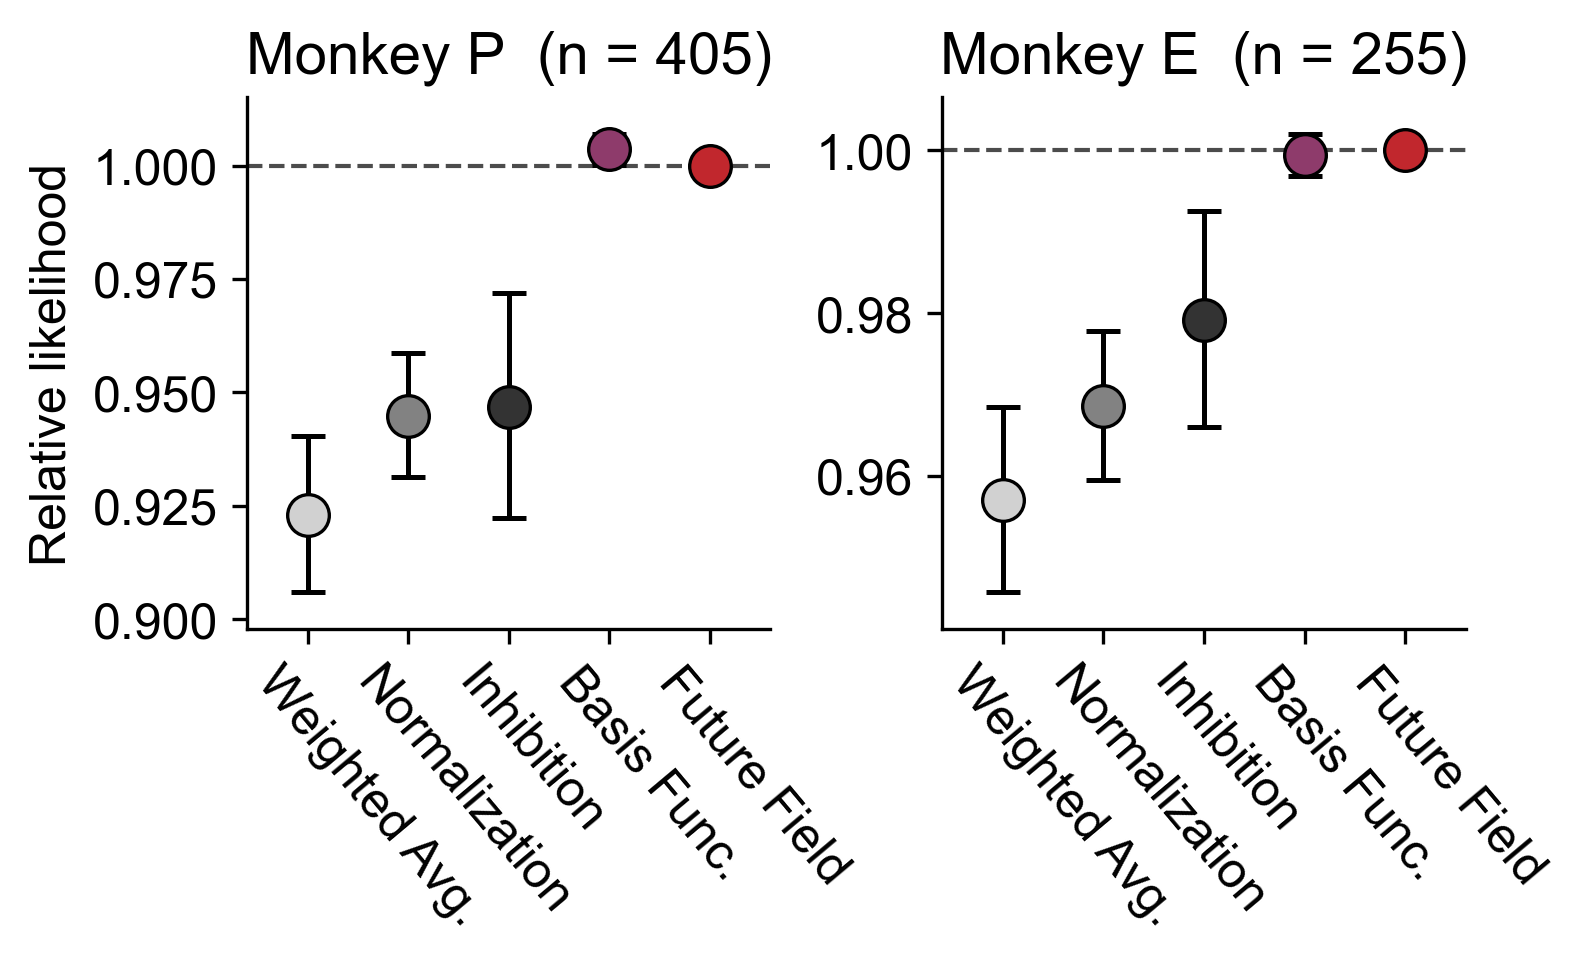

saved figure_model_comparison_DMFC.pdf


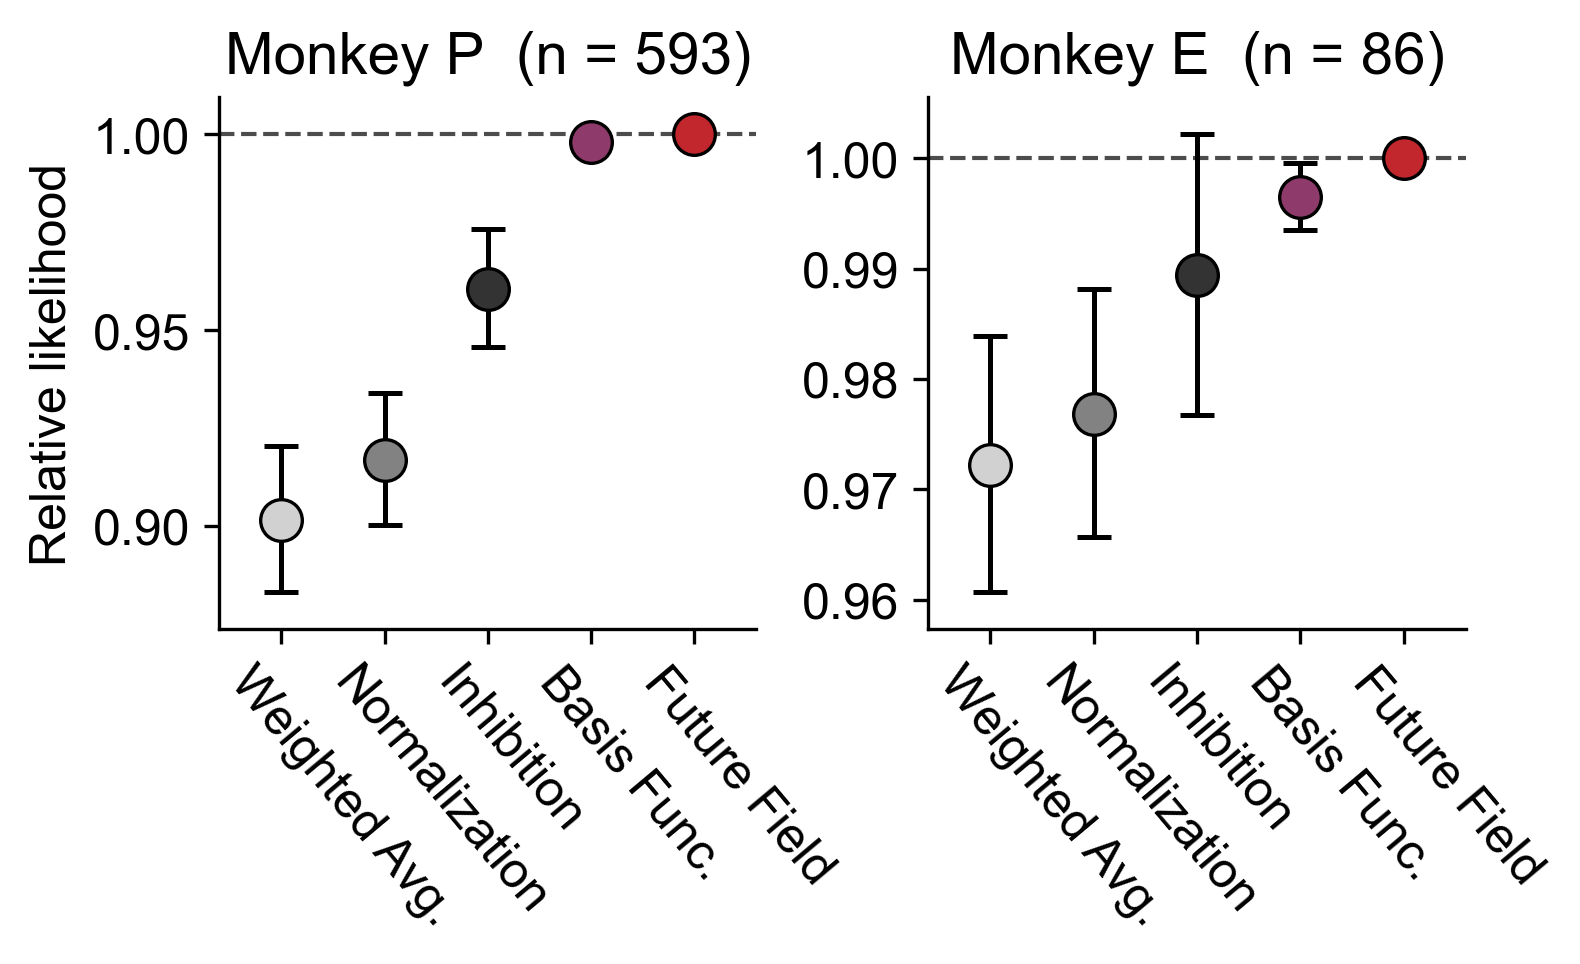

In [3]:
summaries = dict(fits)
for area, per_subject in tables.items():
    pop = summaries[area].drop_duplicates(['subject', 'session', 'unit'])
    n_by_subject = {TITLES[s_]: int((pop['subject'] == s_).sum()) for s_ in SUBJECTS}
    fig = el.plot_elpd(per_subject, COLORS, figsize=FIGSIZE, labels=LABELS,
                       xtick_rotation=XTICK_ROTATION, xtick_ha=XTICK_HA,
                       shift_in=XTICK_SHIFT_IN, n_by_subject=n_by_subject,
                       wspace=WSPACE, column_shift_in=COLUMN_SHIFT_IN, ylabel=YLABEL,
                       point_size=POINT_SIZE, err_linewidth=ERR_LINEWIDTH,
                       err_capsize=ERR_CAPSIZE)
    common.save(fig, OUTPUT.format(area=area))
    plt.show()


## The constant-rate model

Every likelihood here is already measured against a neuron that **ignores the stimulus**, so
that model is the origin of the whole scale. It is printed rather than drawn, as in the main
figure: on this axis it sits far below every model shown, and a line there would flatten them
all against the top.

What it gives is the size of the thing being argued over. The models differ from each other by a
few per cent per trial; they differ from a constant rate by very much more, and the *worst* of
them already recovers most of that distance — which is the reading that has to survive the
conditioning for the supplement to be reassuring.

In [4]:
for area, summary in fits:
    for s_ in SUBJECTS:
        t = tables[area][TITLES[s_]]
        _, units, c0 = el.per_neuron_delta(summary, MODELS, t.attrs['reference'], subject=s_)
        worst = t['delta_per_unit'].min()
        print(f'{area}  {TITLES[s_]}  (reference {t.attrs["reference"]})')
        print(f'    constant rate: {c0:+.4f} nats/trial  ->  relative likelihood '
              f'{np.exp(c0):.4f} per trial, {np.exp(c0 * units["n_2obj"].mean()):.3g} per neuron')
        print(f'    worst model:   {worst:+.4f} nats/trial  ->  {np.exp(worst):.4f} per trial, '
              f'i.e. {100 * (1 - worst / c0):.0f}% of the way from a constant rate to the best')


FEF  Monkey P  (reference future_field)
    constant rate: -0.4549 nats/trial  ->  relative likelihood 0.6345 per trial, 8.85e-146 per neuron
    worst model:   -0.0801 nats/trial  ->  0.9230 per trial, i.e. 82% of the way from a constant rate to the best
FEF  Monkey E  (reference future_field)
    constant rate: -0.2088 nats/trial  ->  relative likelihood 0.8116 per trial, 1.02e-65 per neuron
    worst model:   -0.0439 nats/trial  ->  0.9570 per trial, i.e. 79% of the way from a constant rate to the best
DMFC  Monkey P  (reference future_field)
    constant rate: -0.3354 nats/trial  ->  relative likelihood 0.7150 per trial, 1.37e-120 per neuron
    worst model:   -0.1037 nats/trial  ->  0.9015 per trial, i.e. 69% of the way from a constant rate to the best
DMFC  Monkey E  (reference future_field)
    constant rate: -0.1033 nats/trial  ->  relative likelihood 0.9019 per trial, 1.57e-50 per neuron
    worst model:   -0.0282 nats/trial  ->  0.9722 per trial, i.e. 73% of the way from a co